# SF2980 - Project 1
## Part A, the code part

In [156]:
import numpy as np
import scipy.stats as stats

# 1. Parameters
n = 700
nu = 5
mu = 1
sigma = 0.01
p = 0.975
alpha = 0.05
np.random.seed(37)  # For reproducibility

# True quantile (only for comparison)
theta = stats.t.ppf(p, df=nu, loc=mu, scale=sigma)

# 2. Generate observations
samples = mu + sigma * np.random.standard_t(nu, n)

# 3. Sort in descending order (as in the book)
sorted_samples = np.sort(samples)[::-1]

# Find indices satisfying equation (7.12)
i = 1
while stats.binom.cdf(i - 1, n, 1 - p) <= alpha / 2:
    i += 1
i -= 1

j = 1
while stats.binom.sf(j - 1, n, 1 - p) > alpha / 2:
    j += 1

# 5. Confidence interval
lower_bound = sorted_samples[j - 1]
upper_bound = sorted_samples[i - 1]

# 6. Actual confidence level
confidence = (stats.binom.cdf(j - 1, n, 1 - p)
              - stats.binom.cdf(i - 1, n, 1 - p))

print(f"True quantile: {theta:.6f}")
print(f"Indices: i={i}, j={j}")
print(f"Confidence interval: ({lower_bound:.5f}, {upper_bound:.5f})")
print(f"Confidence level: {confidence:.4%}")



True quantile: 1.025706
Indices: i=10, j=27
Confidence interval: (1.02473, 1.03331)
Confidence level: 96.1473%


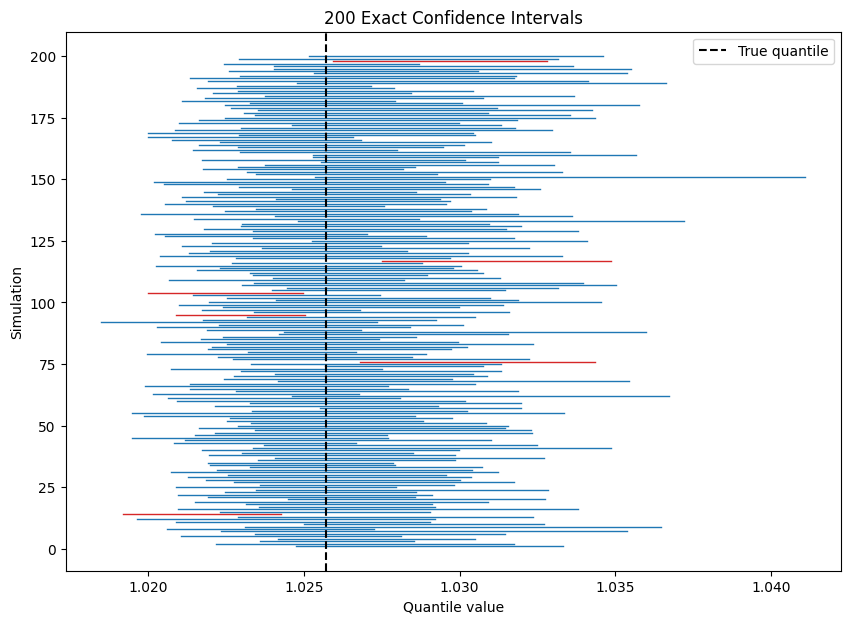

Exact coverage: 194/200
Empirical coverage: 97.00%


In [157]:
# A.1(b) - 200 exact confidence intervals

n = 700
K = 200
nu = 5
mu = 1
sigma = 0.01
p = 0.975
alpha = 0.05

np.random.seed(37)

# True quantile
theta = stats.t.ppf(p, df=nu, loc=mu, scale=sigma)

# Exact confidence interval indices
i = 1
while stats.binom.cdf(i - 1, n, 1 - p) <= alpha / 2:
    i += 1
i -= 1

j = 1
while stats.binom.sf(j - 1, n, 1 - p) > alpha / 2:
    j += 1

# Store confidence intervals
exact_intervals = np.zeros((K, 2))

for k in range(K):

    # Generate 700 observations
    samples = mu + sigma * np.random.standard_t(nu, n)

    # Sort observations in descending order
    sorted_samples = np.sort(samples)[::-1]

    # Construct exact confidence interval
    exact_intervals[k, 0] = sorted_samples[j - 1]
    exact_intervals[k, 1] = sorted_samples[i - 1]

# Check coverage
exact_covered = (
    (exact_intervals[:, 0] < theta) &
    (theta < exact_intervals[:, 1])
)

# Plot confidence intervals
plt.figure(figsize=(10, 7))

for k in range(K):
    color = "tab:blue" if exact_covered[k] else "tab:red"

    plt.plot(
        exact_intervals[k],
        [k + 1, k + 1],
        color=color,
        linewidth=1
    )

plt.axvline(theta, color="black", linestyle="--",
            label="True quantile")

plt.xlabel("Quantile value")
plt.ylabel("Simulation")
plt.title("200 Exact Confidence Intervals")
plt.legend()
plt.show()

print(f"Exact coverage: {exact_covered.sum()}/{K}")
print(f"Empirical coverage: {exact_covered.mean():.2%}")


True VaR: 0.257058


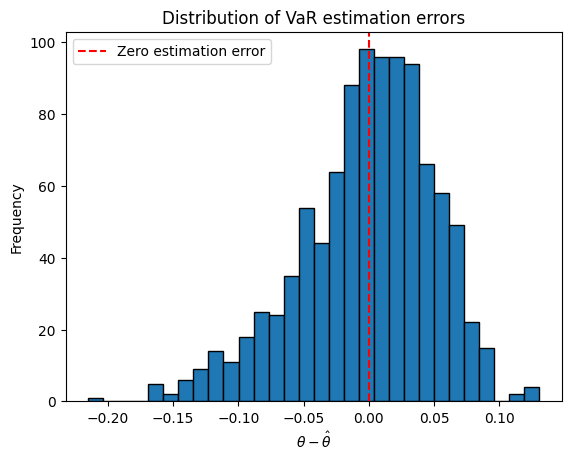

In [158]:
#4.2(a)
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
np.random.seed(37)  # For reproducibility

# Parameters
nu = 5
mu = 1
sigma = 0.01
V0 = 10
p = 0.025

# True Value-at-Risk
theta = V0 * (1 - stats.t.ppf(p, df=nu, loc=mu, scale=sigma))

print(f"True VaR: {theta:.6f}")

# Generate 100 independent returns
n = 100
N = 1000
errors = np.zeros(N)

for i in range(N):
    returns= mu + sigma * np.random.standard_t(nu, n)

    # Convert returns to losses
    losses = V0 * (1 - returns)

    # Sort losses in descending order (book notation)
    sorted_losses = np.sort(losses)[::-1]

    # Empirical VaR: third largest loss
    index = int(np.floor(n * p))
    theta_hat = sorted_losses[index]

    # Estimation error
    error = theta - theta_hat
    errors[i] = error


      
plt.hist(errors, bins=30, edgecolor="black")
plt.axvline(0, color="red", linestyle="--", label="Zero estimation error")
plt.xlabel(r"$\theta - \hat{\theta}$")
plt.ylabel("Frequency")
plt.title("Distribution of VaR estimation errors")
plt.legend()
plt.show()
# the histogram shows the dist of errors, here it's a bit left skewed



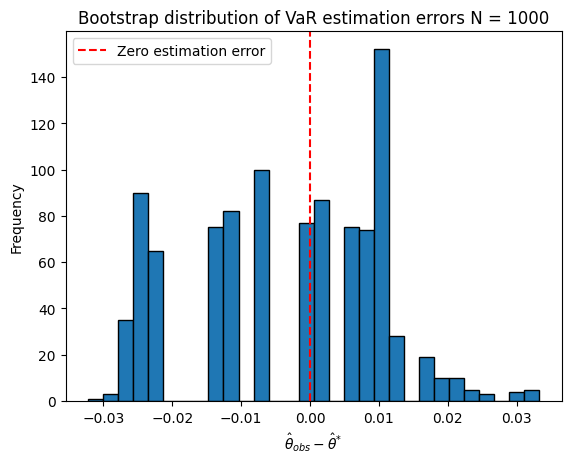

Observed VaR estimate: 0.268657


In [159]:
# A.2(b) - Nonparametric Bootstrap

n = 700
N = 1000
np.random.seed(37)  # For reproducibility

# Generate 700 historical returns
returns = mu + sigma * np.random.standard_t(nu, n)

# Convert returns to losses
losses = V0 * (1 - returns)

# Calculate observed empirical VaR
sorted_losses = np.sort(losses)[::-1]
index = int(np.floor(n * p))
theta_hat_obs = sorted_losses[index]

# Bootstrap simulations
bootstrap_errors = np.zeros(N)


for i in range(N):
    # Resample 700 losses with replacement
    bootstrap_sample = np.random.choice(losses, size=n, replace=True)

    # Calculate empirical VaR for bootstrap sample
    sorted_bootstrap = np.sort(bootstrap_sample)[::-1]
    theta_hat_star = sorted_bootstrap[index]
    

    # Store bootstrap estimation error
    bootstrap_errors[i] = theta_hat_obs - theta_hat_star

# Plot bootstrap histogram
plt.hist(bootstrap_errors, bins=30, edgecolor="black")
plt.axvline(0, color="red", linestyle="--", label="Zero estimation error")
plt.xlabel(r"$\hat{\theta}_{obs} - \hat{\theta}^{*}$")
plt.ylabel("Frequency")
plt.title("Bootstrap distribution of VaR estimation errors N = 1000")
plt.legend()
plt.show()

print(f"Observed VaR estimate: {theta_hat_obs:.6f}")


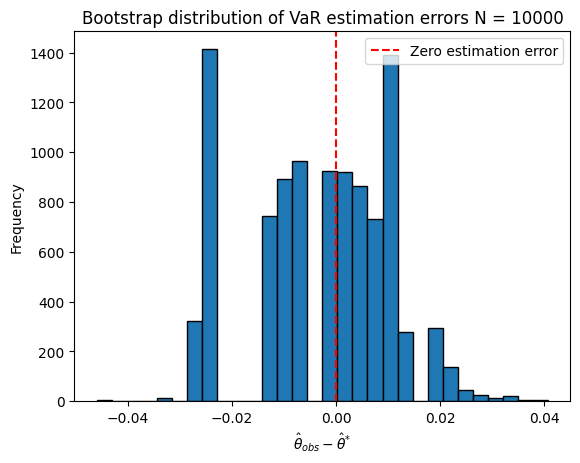

Observed VaR estimate: 0.268657


In [160]:
N = 10000
bootstrap_errors_c = np.zeros(N)

for i in range(N):
    # Resample 700 losses with replacement
    bootstrap_sample = np.random.choice(losses, size=n, replace=True)

    # Calculate empirical VaR for bootstrap sample
    sorted_bootstrap = np.sort(bootstrap_sample)[::-1]
    theta_hat_star = sorted_bootstrap[index]

    # Store bootstrap estimation error
    bootstrap_errors_c[i] = theta_hat_obs - theta_hat_star

plt.hist(bootstrap_errors_c, bins=30, edgecolor="black")
plt.axvline(0, color="red", linestyle="--", label="Zero estimation error")
plt.xlabel(r"$\hat{\theta}_{obs} - \hat{\theta}^{*}$")
plt.ylabel("Frequency")
plt.title("Bootstrap distribution of VaR estimation errors N = 10000")
plt.legend()
plt.show()

print(f"Observed VaR estimate: {theta_hat_obs:.6f}")

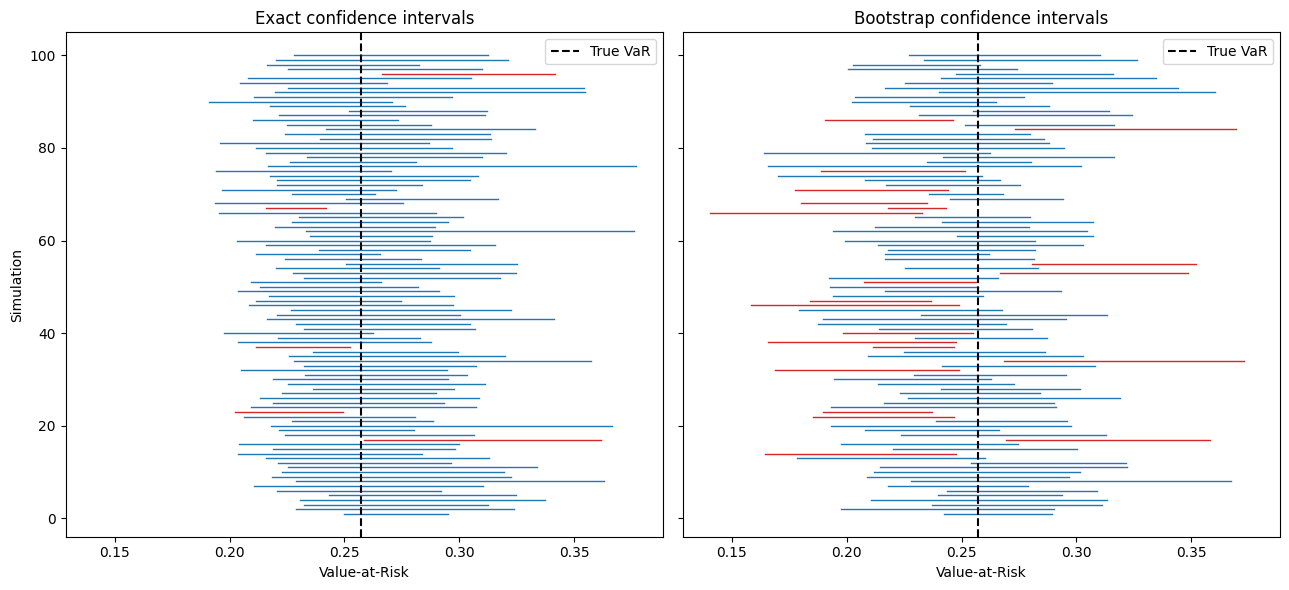

Exact coverage: 95/100
Bootstrap coverage: 79/100


In [161]:
# A.2(d) - Exact vs Bootstrap confidence intervals

n = 700
K = 100
N = 1000
q = 0.95

nu = 5
mu = 1
sigma = 0.01
p = 0.025
alpha = 0.05

np.random.seed(37)

# True VaR
theta = V0 * (1 - stats.t.ppf(p, df=nu, loc=mu, scale=sigma))

# Order statistic indices from A.1
i = 1
while stats.binom.cdf(i - 1, n, p) <= alpha / 2:
    i += 1
i -= 1

j = 1
while stats.binom.sf(j - 1, n, p) > alpha / 2:
    j += 1

# Store confidence intervals
exact_intervals = np.zeros((K, 2))
bootstrap_intervals = np.zeros((K, 2))

# Empirical VaR index
index = int(np.floor(n * p))

for k in range(K):

    # Generate 700 returns and calculate losses
    returns = mu + sigma * np.random.standard_t(nu, n)
    losses = V0 * (1 - returns)

    # Sort losses in descending order
    sorted_losses = np.sort(losses)[::-1]

    # Method 1: Exact confidence interval
    exact_intervals[k, 0] = sorted_losses[j - 1]
    exact_intervals[k, 1] = sorted_losses[i - 1]

    # Method 2: Nonparametric bootstrap
    theta_hat_obs = sorted_losses[index]
    bootstrap_errors = np.zeros(N)

    for b in range(N):
        bootstrap_sample = np.random.choice(
            losses, size=n, replace=True
        )

        sorted_bootstrap = np.sort(bootstrap_sample)[::-1]
        theta_hat_star = sorted_bootstrap[index]

        bootstrap_errors[b] = theta_hat_obs - theta_hat_star

    # Sort bootstrap residuals in descending order
    sorted_errors = np.sort(bootstrap_errors)[::-1]

    # Empirical residual quantiles (book convention)
    lower_idx = int(np.floor(N * (1 + q) / 2))
    upper_idx = int(np.floor(N * (1 - q) / 2))

    bootstrap_intervals[k, 0] = theta_hat_obs + sorted_errors[lower_idx]
    bootstrap_intervals[k, 1] = theta_hat_obs + sorted_errors[upper_idx]



fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharex=True, sharey=True)

methods = [
    (exact_intervals, "Exact confidence intervals"),
    (bootstrap_intervals, "Bootstrap confidence intervals")
]

for ax, (intervals, title) in zip(axes, methods):

    covered = (
        (intervals[:, 0] < theta) &
        (theta < intervals[:, 1])
    )

    for k in range(K):
        color = "tab:blue" if covered[k] else "tab:red"

        ax.plot(
            intervals[k],
            [k + 1, k + 1],
            color=color,
            linewidth=1
        )

    ax.axvline(theta, color="black", linestyle="--",
               label="True VaR")
    ax.set_title(title)
    ax.set_xlabel("Value-at-Risk")
    ax.legend()

axes[0].set_ylabel("Simulation")
plt.tight_layout()
plt.show()


exact_covered = (
    (exact_intervals[:, 0] < theta) &
    (theta < exact_intervals[:, 1])
)

bootstrap_covered = (
    (bootstrap_intervals[:, 0] < theta) &
    (theta < bootstrap_intervals[:, 1])
)

print(f"Exact coverage: {exact_covered.sum()}/{K}")
print(f"Bootstrap coverage: {bootstrap_covered.sum()}/{K}")
